In [1]:
import mne
raw = mne.io.read_raw_edf("../data/raw/h01.edf", preload=True)

Extracting EDF parameters from ../data/raw/h01.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 231249  =      0.000 ...   924.996 secs...


In [2]:
print("Électrodes :", raw.ch_names)
print("Nombre d'électrodes :", len(raw.ch_names))
print("Mesures par seconde :", raw.info["sfreq"])
print("Durée (secondes) :", raw.times[-1])
print("Taille du tableau :", raw.get_data().shape)

Électrodes : ['Fp2', 'F8', 'T4', 'T6', 'O2', 'Fp1', 'F7', 'T3', 'T5', 'O1', 'F4', 'C4', 'P4', 'F3', 'C3', 'P3', 'Fz', 'Cz', 'Pz']
Nombre d'électrodes : 19
Mesures par seconde : 250.0
Durée (secondes) : 924.996
Taille du tableau : (19, 231250)


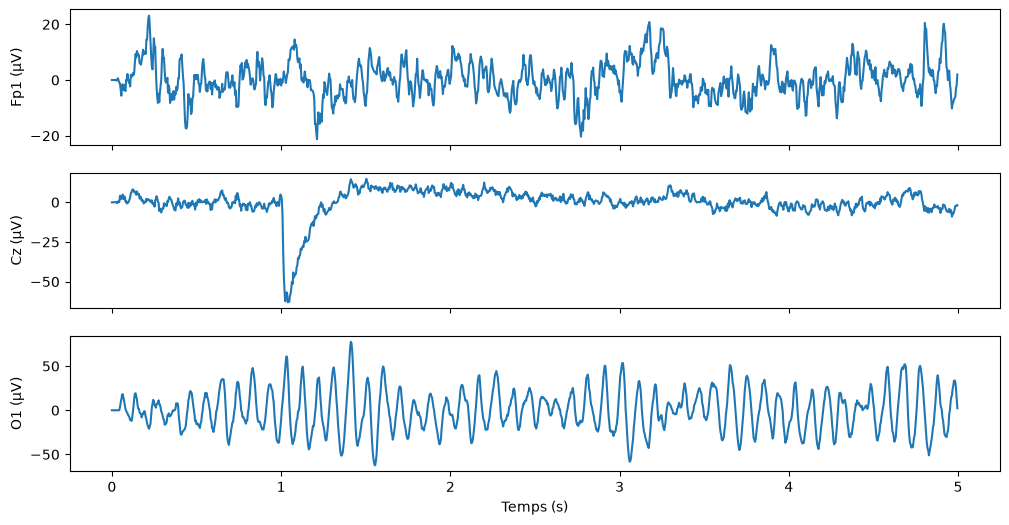

In [3]:
import matplotlib.pyplot as plt

donnees = raw.get_data()
temps = raw.times
n = 5 * 250

noms = ["Fp1", "Cz", "O1"]
fig, axes = plt.subplots(len(noms), 1, figsize=(12, 6), sharex=True)

for k in range(len(noms)):
    i = raw.ch_names.index(noms[k])
    axes[k].plot(temps[:n], donnees[i, :n] * 1e6)
    axes[k].set_ylabel(noms[k] + " (µV)")

axes[-1].set_xlabel("Temps (s)")
plt.show()

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 825 samples (3.300 s)



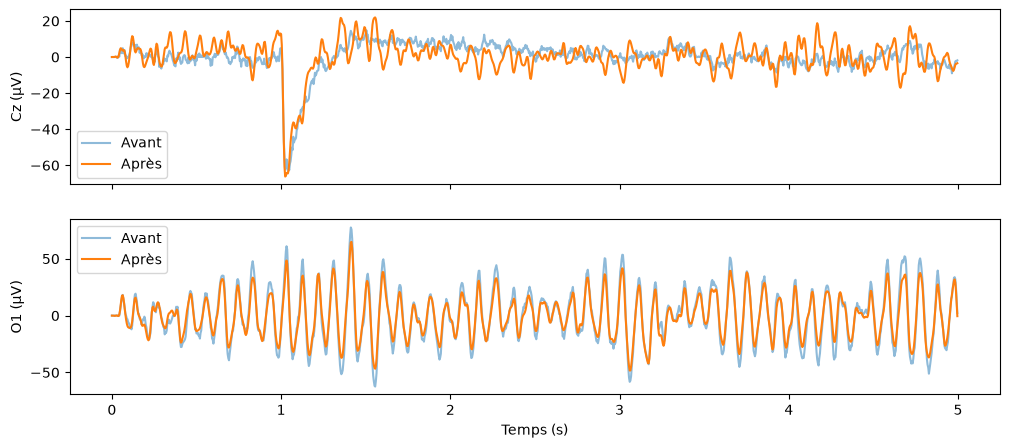

In [4]:
raw_propre = raw.copy()
raw_propre.set_eeg_reference()
raw_propre.filter(l_freq=1, h_freq=45)

avant = raw.get_data()
apres = raw_propre.get_data()

noms = ["Cz", "O1"]
fig, axes = plt.subplots(len(noms), 1, figsize=(12, 5), sharex=True)

for k in range(len(noms)):
    i = raw.ch_names.index(noms[k])
    axes[k].plot(temps[:n], avant[i, :n] * 1e6, label="Avant", alpha=0.5)
    axes[k].plot(temps[:n], apres[i, :n] * 1e6, label="Après")
    axes[k].set_ylabel(noms[k] + " (µV)")
    axes[k].legend()

axes[-1].set_xlabel("Temps (s)")
plt.show()

In [5]:
epochs = mne.make_fixed_length_epochs(raw_propre, duration=25, preload=True)
print("Taille :", epochs.get_data().shape)

Not setting metadata
37 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 37 events and 6250 original time points ...
0 bad epochs dropped
Taille : (37, 19, 6250)
